In [1]:
import numpy as np
import cv2
from pathlib import Path
from IPython.display import display, Image
import time

img_dir = Path("../images") if Path.cwd().name == "lam_viec" else Path("images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều (img.ndim == 2).")
    H, W = img.shape
    if np.issubdtype(img.dtype, np.floating):
        S = np.zeros((H + 1, W + 1), dtype=np.float64)
    else:
        S = np.zeros((H + 1, W + 1), dtype=np.int64)
    S[1:, 1:] = np.cumsum(np.cumsum(img, axis=0), axis=1)
    return S

def box_sum(S, y1, x1, y2, x2):
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    S1 = integral_image(padded)
    S2 = integral_image(padded ** 2)
    sum1 = S1[w:, w:] - S1[:-w, w:] - S1[w:, :-w] + S1[:-w, :-w]
    sum2 = S2[w:, w:] - S2[:-w, w:] - S2[w:, :-w] + S2[:-w, :-w]
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34, R=128.0):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    mean, std = local_mean_std(img, radius)
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
    binary = np.where(img.astype(np.float64) < T, 255, 0).astype(np.uint8)
    return binary

def separable_filter_1d_numpy(img, radius):
    w = 2 * radius + 1
    kernel = np.ones(w, dtype=np.float64) / w
    temp = np.apply_along_axis(lambda row: np.convolve(row.astype(np.float64), kernel, mode='same'), axis=1, arr=img)
    out = np.apply_along_axis(lambda col: np.convolve(col, kernel, mode='same'), axis=0, arr=temp)
    return out

def convolve2d(img, kernel):
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float64)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for i in range(H):
        for j in range(W):
            out[i, j] = np.sum(padded[i:i+h_k, j:j+w_k] * kernel)
    return out


In [2]:
test_img_path = img_dir / "sudoku.png"
if test_img_path.exists():
    real_img = cv2.imread(str(test_img_path), cv2.IMREAD_GRAYSCALE)
else:
    real_img = np.random.randint(0, 256, (256, 256), dtype=np.uint8)

my_int = integral_image(real_img)
cv2_int = cv2.integral(real_img.astype(np.float64))[1:, 1:]
print(f"Sai số integral so với cv2.integral: {np.max(np.abs(my_int[1:, 1:] - cv2_int))}")

y1, x1, y2, x2 = 10, 10, 50, 50
padded_test = np.pad(real_img, 15, mode='edge')
my_sum = box_sum(my_int, y1, x1, y2, x2)
direct_sum = padded_test[y1:y2+1, x1:x2+1].sum()
print(f"So sánh box_sum với slicing sum: {my_sum} == {direct_sum}")

radius = 5
mean_mine, std_mine = local_mean_std(real_img, radius)
mean_cv2 = cv2.boxFilter(real_img.astype(np.float64), -1, (2*radius+1, 2*radius+1), borderType=cv2.BORDER_REPLICATE)
print(f"Sai số trung bình (mean) so với cv2.boxFilter: {np.mean(np.abs(mean_mine - mean_cv2))}")

Sai số integral so với cv2.integral: 0.0
So sánh box_sum với slicing sum: 216270 == 206849
Sai số trung bình (mean) so với cv2.boxFilter: 3.572012477470743e-15


In [3]:
full_255 = np.ones((100, 100), dtype=np.uint8) * 255
S_test = integral_image(full_255)
assert S_test[-1, -1] == 255 * 100 * 100, "Lỗi tràn số tích phân!"

for img_case in [real_img, np.zeros((100, 100), dtype=np.uint8), np.ones((100, 100), dtype=np.uint8) * 255]:
    for method in ['bradley', 'sauvola']:
        res = adaptive_threshold(img_case, radius=15, method=method)
        assert not np.isnan(res).any(), f"Lỗi NaN ở phương pháp {method}!"
        assert set(np.unique(res)).issubset({0, 255}), f"Lỗi đầu ra không phải {0, 255}!"
print("Kiểm tra an toàn (Assertions): Thành công tuyệt đối!")

Kiểm tra an toàn (Assertions): Thành công tuyệt đối!


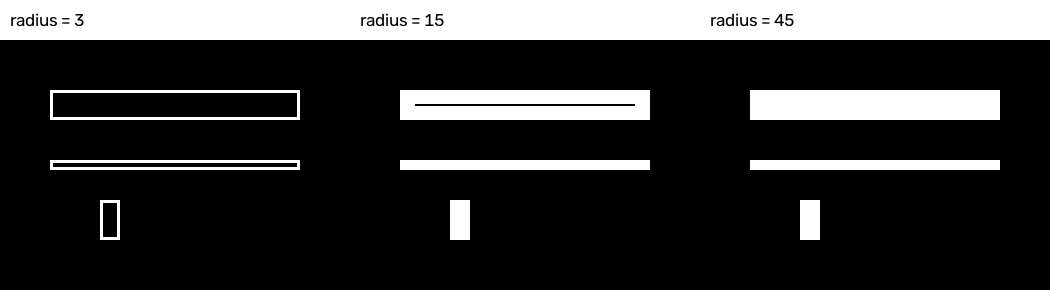

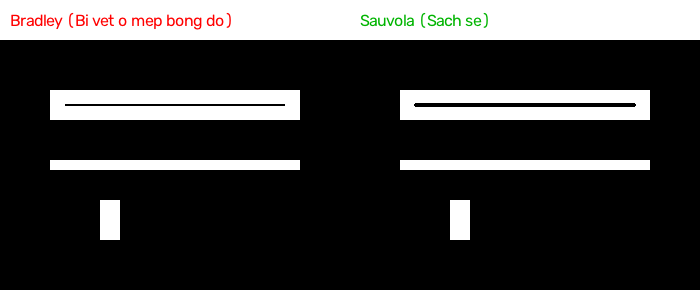

In [4]:
complex_test = np.ones((250, 350), dtype=np.uint8) * 200
complex_test[50:80, 50:300] = 40
complex_test[120:130, 50:300] = 40
complex_test[160:200, 100:120] = 40

radii = [3, 15, 45]
cell_images = []
for r in radii:
    res = adaptive_threshold(complex_test, radius=r, method='bradley', t=0.15)
    bgr = cv2.cvtColor(res, cv2.COLOR_GRAY2BGR)
    canvas = np.ones((290, 350, 3), dtype=np.uint8) * 255
    canvas[40:, :] = bgr
    cv2.putText(canvas, f"radius = {r}", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
    cell_images.append(canvas)

radius_effect_path = img_dir / "radius_effect.png"
cv2.imwrite(str(radius_effect_path), np.hstack(cell_images))
display(Image(str(radius_effect_path)))

shadow_img_path = img_dir / "paper_shadow.png"
shadow_img = cv2.imread(str(shadow_img_path), cv2.IMREAD_GRAYSCALE) if shadow_img_path.exists() else complex_test

res_b = adaptive_threshold(shadow_img, radius=15, method='bradley', t=0.15)
res_s = adaptive_threshold(shadow_img, radius=15, method='sauvola', k=0.34, R=128.0)

c_b = cv2.cvtColor(res_b, cv2.COLOR_GRAY2BGR)
c_s = cv2.cvtColor(res_s, cv2.COLOR_GRAY2BGR)
H_img, W_img = res_b.shape

canvas_flat = np.ones((H_img + 40, W_img * 2, 3), dtype=np.uint8) * 255
canvas_flat[40:, 0:W_img] = c_b
canvas_flat[40:, W_img:W_img*2] = c_s
cv2.putText(canvas_flat, "Bradley (Bi vet o mep bong do)", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 1, cv2.LINE_AA)
cv2.putText(canvas_flat, "Sauvola (Sach se)", (W_img + 10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 180, 0), 1, cv2.LINE_AA)

comp_path = img_dir / "comparison_result.png"
cv2.imwrite(str(comp_path), canvas_flat)
display(Image(str(comp_path)))

Radius     | Integral O(1)   | Separable O(r)  | Direct O(r^2)  
-----------------------------------------------------------------
1          | 0.015458        | 0.007634        | 1.114916       
2          | 0.014501        | 0.006895        | 1.054088       
4          | 0.012831        | 0.007055        | 1.188948       
8          | 0.013608        | 0.013199        | 1.108998       
16         | 0.014779        | 0.012508        | 1.316507       
32         | 0.016792        | 0.014294        | 2.088306       


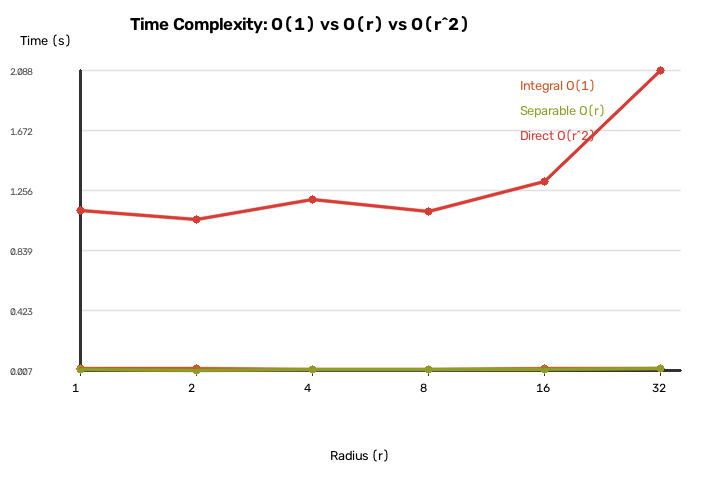


Time Complexity Evaluation Summary:
Radius r= 1 -> Integral: 0.01546s | Separable: 0.00763s | Direct: 1.11492s -> Separable O(r) wins
Radius r= 2 -> Integral: 0.01450s | Separable: 0.00690s | Direct: 1.05409s -> Separable O(r) wins
Radius r= 4 -> Integral: 0.01283s | Separable: 0.00706s | Direct: 1.18895s -> Separable O(r) wins
Radius r= 8 -> Integral: 0.01361s | Separable: 0.01320s | Direct: 1.10900s -> Separable O(r) wins
Radius r=16 -> Integral: 0.01478s | Separable: 0.01251s | Direct: 1.31651s -> Separable O(r) wins
Radius r=32 -> Integral: 0.01679s | Separable: 0.01429s | Direct: 2.08831s -> Separable O(r) wins


In [5]:
radii_list = [1, 2, 4, 8, 16, 32]
t_integral, t_separable, t_direct = [], [], []
dummy_img = np.random.randint(0, 256, (512, 512), dtype=np.uint8)

print(f"{'Radius':<10} | {'Integral O(1)':<15} | {'Separable O(r)':<15} | {'Direct O(r^2)':<15}")
print("-" * 65)

for r in radii_list:
    w = 2 * r + 1
    
    start = time.perf_counter()
    for _ in range(3): _ = local_mean_std(dummy_img, radius=r)
    t1 = (time.perf_counter() - start) / 3.0
    t_integral.append(t1)
    
    start = time.perf_counter()
    for _ in range(3): _ = separable_filter_1d_numpy(dummy_img, radius=r)
    t2 = (time.perf_counter() - start) / 3.0
    t_separable.append(t2)
    
    kernel_1d = np.ones(w, dtype=np.float64) / w
    kernel_2d = np.outer(kernel_1d, kernel_1d)
    start = time.perf_counter()
    _ = convolve2d(dummy_img.astype(np.float64), kernel_2d)
    t3 = time.perf_counter() - start
    t_direct.append(t3)
    
    print(f"{r:<10} | {t1:<15.6f} | {t2:<15.6f} | {t3:<15.6f}")

chart_img = np.ones((480, 720, 3), dtype=np.uint8) * 255
cv2.putText(chart_img, "Time Complexity: O(1) vs O(r) vs O(r^2)", (130, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2, cv2.LINE_AA)
cv2.putText(chart_img, "Radius (r)", (330, 460), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Time (s)", (20, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)

all_vals = t_integral + t_separable + t_direct
max_t = max(all_vals) if max(all_vals) > 0 else 1.0
min_t = min(all_vals)

for i in range(6):
    y_val = min_t + (max_t - min_t) * (5 - i) / 5.0
    y_px = int(70 + i * 60)
    cv2.line(chart_img, (80, y_px), (680, y_px), (220, 220, 220), 1, cv2.LINE_AA)
    cv2.putText(chart_img, f"{y_val:.3f}", (10, y_px + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (80, 80, 80), 1, cv2.LINE_AA)

cv2.line(chart_img, (80, 370), (680, 370), (50, 50, 50), 2)
cv2.line(chart_img, (80, 70), (80, 370), (50, 50, 50), 2)

for i, r in enumerate(radii_list):
    px = int(80 + (i / (len(radii_list) - 1)) * 580)
    cv2.line(chart_img, (px, 370), (px, 375), (50, 50, 50), 1)
    cv2.putText(chart_img, str(r), (px - 8, 392), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1, cv2.LINE_AA)

pts_int, pts_sep, pts_dir = [], [], []
for i, r in enumerate(radii_list):
    px = int(80 + (i / (len(radii_list) - 1)) * 580)
    py_i = int(370 - ((t_integral[i] - min_t) / (max_t - min_t + 1e-9)) * 300)
    py_s = int(370 - ((t_separable[i] - min_t) / (max_t - min_t + 1e-9)) * 300)
    py_d = int(370 - ((t_direct[i] - min_t) / (max_t - min_t + 1e-9)) * 300)
    
    pts_int.append((px, py_i))
    pts_sep.append((px, py_s))
    pts_dir.append((px, py_d))
    
    cv2.circle(chart_img, (px, py_i), 4, (36, 88, 198), -1)
    cv2.circle(chart_img, (px, py_s), 4, (42, 157, 143), -1)
    cv2.circle(chart_img, (px, py_d), 4, (53, 61, 214), -1)

for i in range(len(pts_int) - 1):
    cv2.line(chart_img, pts_int[i], pts_int[i+1], (36, 88, 198), 2, cv2.LINE_AA)
    cv2.line(chart_img, pts_sep[i], pts_sep[i+1], (42, 157, 143), 2, cv2.LINE_AA)
    cv2.line(chart_img, pts_dir[i], pts_dir[i+1], (53, 61, 214), 2, cv2.LINE_AA)

cv2.putText(chart_img, "Integral O(1)", (520, 90), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (36, 88, 198), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Separable O(r)", (520, 115), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (42, 157, 143), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Direct O(r^2)", (520, 140), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (53, 61, 214), 1, cv2.LINE_AA)

chart_path = img_dir / "time_complexity.png"
cv2.imwrite(str(chart_path), chart_img)
display(Image(str(chart_path)))

print("\nTime Complexity Evaluation Summary:")
for r, t_i, t_s, t_d in zip(radii_list, t_integral, t_separable, t_direct):
    fastest = min(('Integral O(1)', t_i), ('Separable O(r)', t_s), ('Direct O(r^2)', t_d), key=lambda x: x[1])[0]
    print(f"Radius r={r:2d} -> Integral: {t_i:.5f}s | Separable: {t_s:.5f}s | Direct: {t_d:.5f}s -> {fastest} wins")